<a href="https://colab.research.google.com/github/asteriaji/MSSP6070/blob/main/WeeklyModules/Week10/Jiangyu_Ji_PARTICIPATION_ACTIVITY_Week_10_Improving_Coding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'asteriaji'
repository = 'MSSP6070'
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Repository already exists. Using the existing copy.
Current directory: /content/MSSP6070
Files in repository:
Adding_File_Structure.py
Assignment_Template.ipynb
Assignments/.gitkeep
Assignments/Assignment 1/Corrected_Version_Jiangyu_Ji_MSSP_6070_Assignment_1.ipynb
Assignments/Assignment 1/Jiangyu_Ji_MSSP_6070_Assignment_1_260930.ipynb
Assignments/Assignment 2/1
Assignments/Assignment 2/Jiangyu_Ji_Assignment_2.ipynb
WeeklyModules/.gitkeep
WeeklyModules/Week01/.gitkeep
WeeklyModules/Week01/1_introducing_matplotlib_(1).ipynb
WeeklyModules/Week01/Week1_Jiangyu_Ji_Participation_Activity_Exercises_260828.ipynb
WeeklyModules/Week01/stats_viz (1).py
WeeklyModules/Week02/.gitkeep
WeeklyModules/Week02/Week2_Jiangyu_Ji_Participation_Activity_260907__(2).ipynb
WeeklyModules/Week02/Week_2_Data_Stuctures.ipynb
WeeklyModules/Week03/.gitkeep
WeeklyModules/Week03/Week_3_Jiangyu_Ji_PARTICIPATION_ACTIVITY_(3)_(2).ipynb
WeeklyModules/Week04/.gitkeep
WeeklyModules/Week04/Jiangyu_Ji_Assignment_PARTICIPATION

In [21]:
# 1.Load the Internet Sales Data Set

In [22]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = repo_path /'data'/'InternetSales.csv'

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH,encoding="latin1")

date_cols = ["OrderDate", "DueDate", "ShipDate"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df["Year"] = df["OrderDate"].dt.year

print("Data loaded successfully!")
print("Data shape:", df.shape)
display(df.head())

Data loaded successfully!
Data shape: (60398, 61)


/tmp/ipykernel_1149/580023774.py:15: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH,encoding="latin1")


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate,Year
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.15,3399.99,272.00,85.00,NaN,NaN,2011-01-19,2011-01-31,2011-01-26,2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.62,2319.99,185.60,58.00,NaN,NaN,2013-01-18,2013-01-30,2013-01-25,2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.22,21.98,1.76,0.55,NaN,NaN,2013-01-18,2013-01-30,2013-01-25,2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.94,2384.07,190.73,59.60,NaN,NaN,2013-05-03,2013-05-15,2013-05-10,2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.84,28.99,2.32,0.72,NaN,NaN,2013-05-03,2013-05-15,2013-05-10,2013


In [23]:
# 2.Create an Internet Sales forecast for the next five years

In [24]:
# Annual Sales Forecast

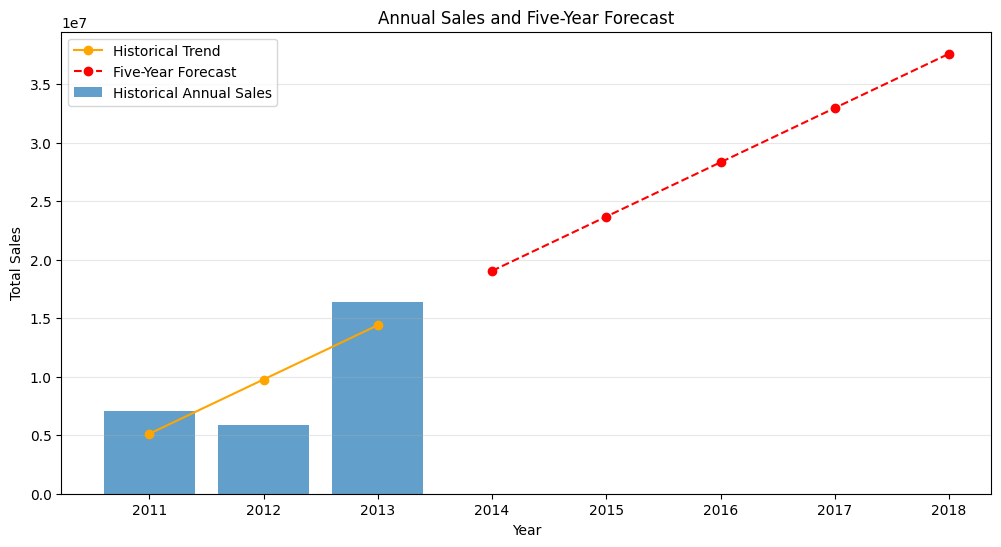

,Year,Annual_Forecast
0,2014,19032544.90
1,2015,23670557.10
2,2016,28308569.31
3,2017,32946581.52
4,2018,37584593.72


In [25]:
df_new = df.query('"2011-01-01" <= OrderDate <= "2013-12-31"').copy()

# Aggregate annual sales
annual_sales = (
    df_new.groupby("Year", as_index=False)
    .agg({"SalesAmount": "sum"})
    .sort_values("Year")
)

# Fit a linear trend
annual_x = annual_sales["Year"].to_numpy()
annual_y = annual_sales["SalesAmount"].to_numpy()

annual_coef = np.polyfit(annual_x, annual_y, 1)
annual_model = np.poly1d(annual_coef)

# Forecast the next five years
future_years = np.arange(annual_x.max() + 1, annual_x.max() + 6)
annual_forecast = annual_model(future_years)

# Store annual forecast results
annual_forecast_df = pd.DataFrame({
    "Year": future_years,
    "Annual_Forecast": annual_forecast
})

# Visualize annual sales and forecast
plt.figure(figsize=(12, 6))

plt.bar(
    annual_sales["Year"],
    annual_sales["SalesAmount"],
    label="Historical Annual Sales",
    alpha=0.7
)

plt.plot(
    annual_sales["Year"],
    annual_model(annual_x),
    color="orange",
    marker="o",
    label="Historical Trend"
)

plt.plot(
    future_years,
    annual_forecast,
    color="red",
    marker="o",
    linestyle="--",
    label="Five-Year Forecast"
)

plt.title("Annual Sales and Five-Year Forecast")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

annual_forecast_df

In [26]:
# Monthly Sales Forecast

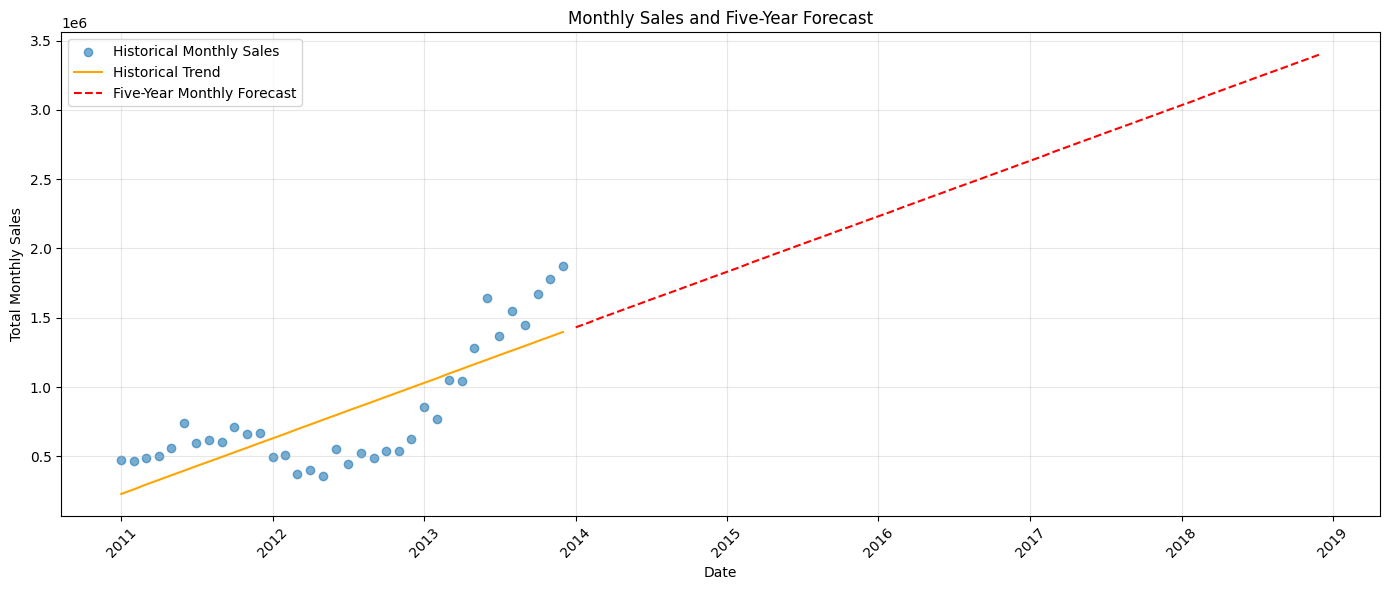

,OrderDate,Monthly_Forecast
0,2014-01-01,1430817.06
1,2014-02-01,1464210.23
2,2014-03-01,1497603.40
3,2014-04-01,1530996.58
4,2014-05-01,1564389.75


In [27]:
# Make sure OrderDate is in datetime format
df_new["OrderDate"] = pd.to_datetime(df_new["OrderDate"])

# Aggregate sales by month
monthly_sales = (
    df_new.set_index("OrderDate")["SalesAmount"]
    .resample("MS")
    .sum()
    .reset_index()
)

# Create a sequential month number
monthly_sales["MonthNumber"] = np.arange(len(monthly_sales))

# Fit a linear trend using monthly data
monthly_x = monthly_sales["MonthNumber"].to_numpy()
monthly_y = monthly_sales["SalesAmount"].to_numpy()

monthly_coef = np.polyfit(monthly_x, monthly_y, 1)
monthly_model = np.poly1d(monthly_coef)

# Forecast the next 60 months
future_month_numbers = np.arange(
    len(monthly_sales),
    len(monthly_sales) + 60
)

monthly_forecast = monthly_model(future_month_numbers)

# Generate future month dates
future_month_dates = pd.date_range(
    start=monthly_sales["OrderDate"].max() + pd.offsets.MonthBegin(1),
    periods=60,
    freq="MS"
)

# Store monthly forecast results
monthly_forecast_df = pd.DataFrame({
    "OrderDate": future_month_dates,
    "Monthly_Forecast": monthly_forecast
})

# Visualize monthly sales and forecast
plt.figure(figsize=(14, 6))

plt.scatter(
    monthly_sales["OrderDate"],
    monthly_sales["SalesAmount"],
    label="Historical Monthly Sales",
    alpha=0.6
)

plt.plot(
    monthly_sales["OrderDate"],
    monthly_model(monthly_x),
    color="orange",
    label="Historical Trend"
)

plt.plot(
    monthly_forecast_df["OrderDate"],
    monthly_forecast,
    color="red",
    linestyle="--",
    label="Five-Year Monthly Forecast"
)

plt.title("Monthly Sales and Five-Year Forecast")
plt.xlabel("Date")
plt.ylabel("Total Monthly Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

monthly_forecast_df.head()

In [28]:
# Comparison

In [29]:
# Aggregate monthly forecasts into annual totals
monthly_annual_forecast = (
    monthly_forecast_df
    .assign(Year=monthly_forecast_df["OrderDate"].dt.year)
    .groupby("Year", as_index=False)
    .agg({"Monthly_Forecast": "sum"})
)

# Merge the two forecast results
forecast_comparison = pd.merge(
    annual_forecast_df,
    monthly_annual_forecast,
    on="Year"
)

# Calculate the difference between the two forecasts
forecast_comparison["Difference"] = (
    forecast_comparison["Monthly_Forecast"]
    - forecast_comparison["Annual_Forecast"]
)

forecast_comparison["Percentage_Difference"] = (
    forecast_comparison["Difference"]
    / forecast_comparison["Annual_Forecast"]
    * 100
)

forecast_comparison

,Year,Annual_Forecast,Monthly_Forecast,Difference,Percentage_Difference
0,2014,19032544.90,19373754.06,341209.17,1.79
1,2015,23670557.10,24182370.85,511813.75,2.16
2,2016,28308569.31,28990987.64,682418.33,2.41
3,2017,32946581.52,33799604.43,853022.91,2.59
4,2018,37584593.72,38608221.22,1023627.50,2.72


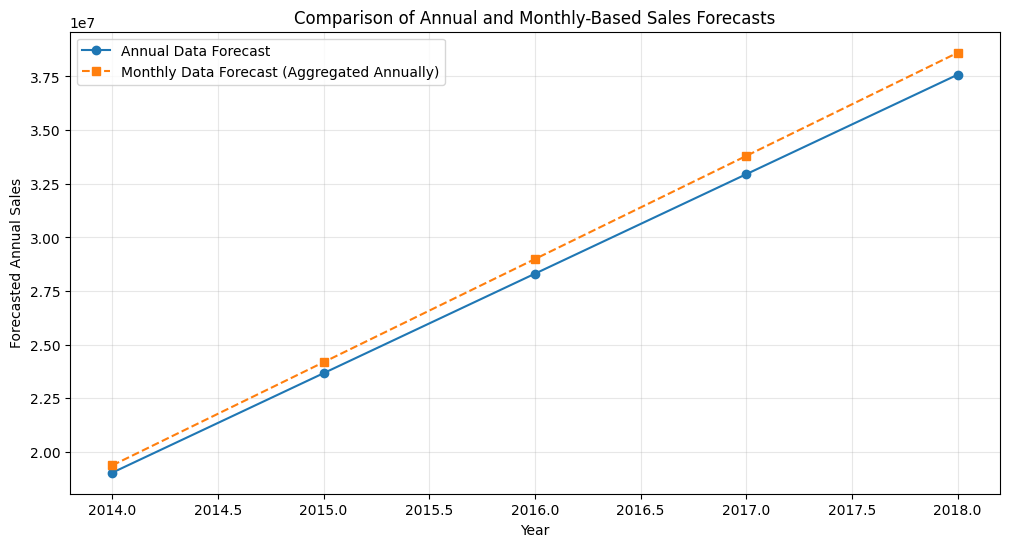

In [30]:
# Compare annual and monthly-based forecasts
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_comparison["Year"],
    forecast_comparison["Annual_Forecast"],
    marker="o",
    label="Annual Data Forecast"
)

plt.plot(
    forecast_comparison["Year"],
    forecast_comparison["Monthly_Forecast"],
    marker="s",
    linestyle="--",
    label="Monthly Data Forecast (Aggregated Annually)"
)

plt.title("Comparison of Annual and Monthly-Based Sales Forecasts")
plt.xlabel("Year")
plt.ylabel("Forecasted Annual Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
# 3.Which product will generate the most sales?

In [32]:
# Aggregate sales and cost by product
product_analysis = (
    df.groupby("EnglishProductName")
      .agg(
          Total_Sales=("SalesAmount", "sum"),
          Total_Cost=("TotalProductCost", "sum")
      )
)

# Calculate profit
product_analysis["Total_Profit"] = (
    product_analysis["Total_Sales"] - product_analysis["Total_Cost"]
)

# Sort products by sales
product_analysis = product_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

# Top-selling product
top_product = product_analysis.iloc[0]
top_product_name = product_analysis.index[0]
top_product_sales = top_product["Total_Sales"]

# Calculate total sales and sales share
total_sales = df["SalesAmount"].sum()
top_product_share = top_product_sales / total_sales * 100

print(f"Top-selling product: {top_product_name}")
print(f"Product sales: ${top_product_sales:,.2f}")
print(f"Product profit: ${top_product['Total_Profit']:,.2f}")
print(f"Total sales: ${total_sales:,.2f}")
print(f"Share of total sales: {top_product_share:.2f}%")

# Display the top 10 products
top_10_products = product_analysis.head(10)

top_10_products

Top-selling product: Mountain-200 Black, 46
Product sales: $1,373,469.55
Product profit: $626,621.57
Total sales: $29,358,677.22
Share of total sales: 4.68%


,Total_Sales,Total_Cost,Total_Profit
EnglishProductName,,,
"Mountain-200 Black, 46",1373469.55,746847.97,626621.57
"Mountain-200 Black, 42",1363142.09,741382.49,621759.61
"Mountain-200 Silver, 38",1339462.79,728598.36,610864.43
"Mountain-200 Silver, 46",1301100.10,707609.63,593490.47
"Mountain-200 Black, 38",1294866.14,704388.68,590477.46
"Mountain-200 Silver, 42",1257434.57,683922.64,573511.94
"Road-150 Red, 48",1205876.99,731726.15,474150.84
"Road-150 Red, 62",1202298.72,729554.85,472743.87
"Road-150 Red, 52",1080637.54,655730.85,424906.69


In [33]:
# Top 10 Products by Sales

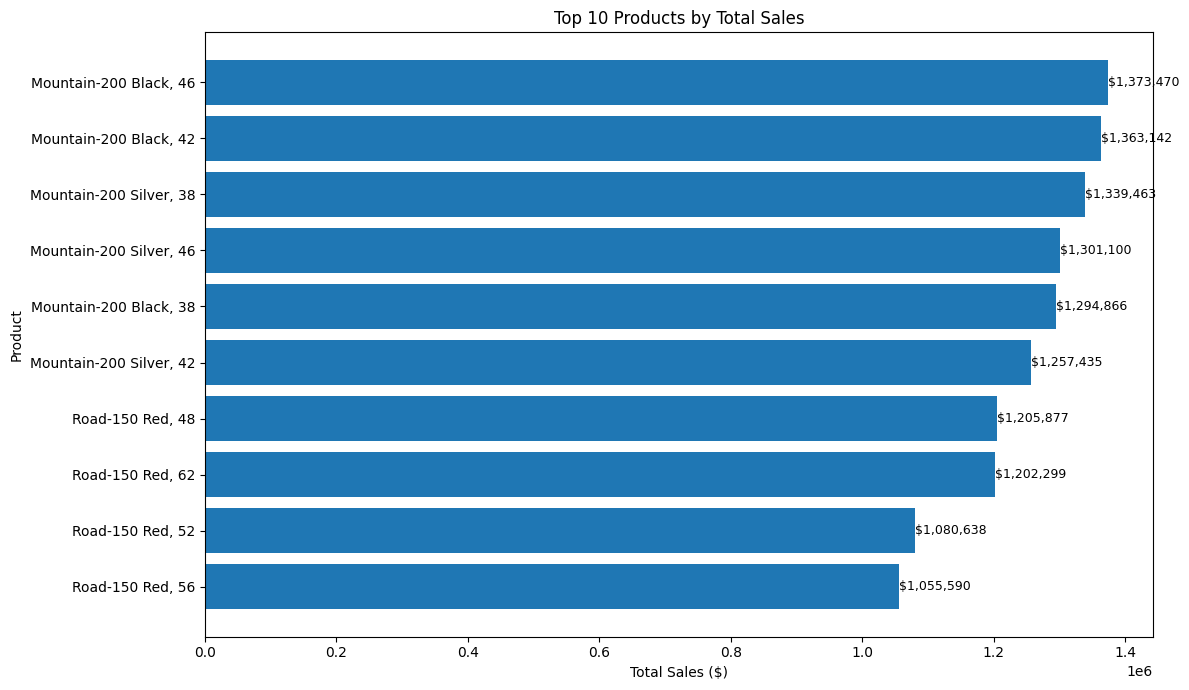

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_products.index[::-1],
    top_10_products["Total_Sales"][::-1]
)

# Add data labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [35]:
# Top 10 Products by Profits

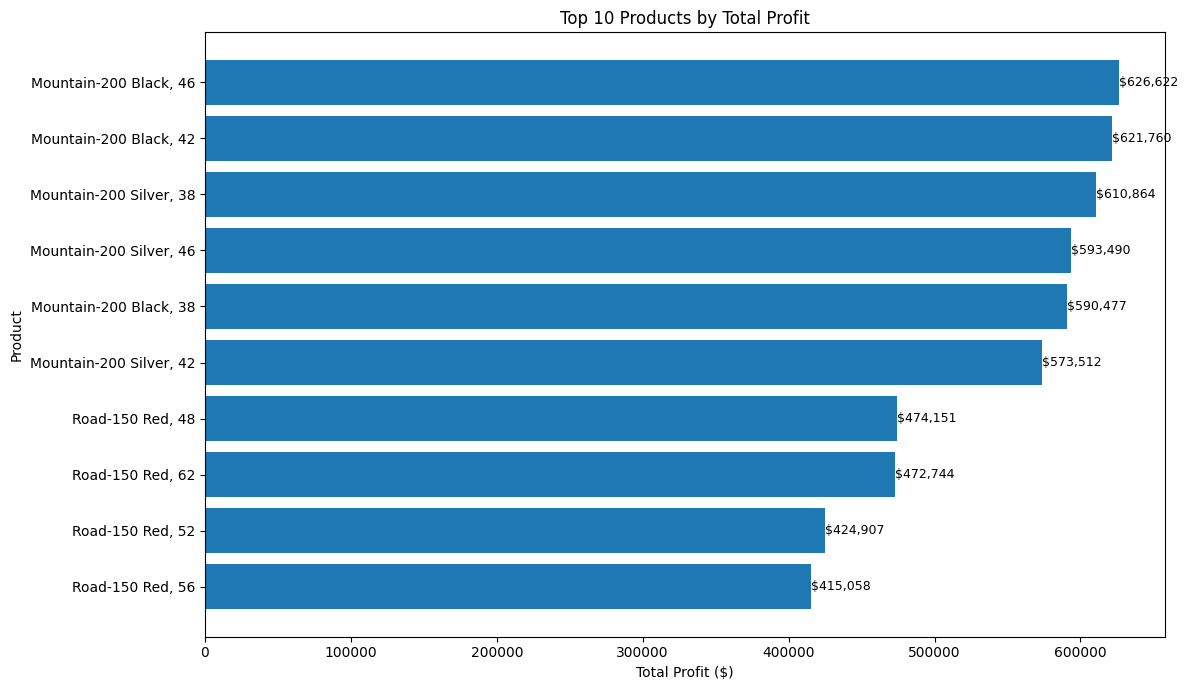

In [36]:
# Sort products by profit
top_10_profit = product_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top_10_profit.index[::-1],
    top_10_profit["Total_Profit"][::-1]
)

# Add data labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.title("Top 10 Products by Total Profit")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [37]:
# 4.Plot a trend line on the sales

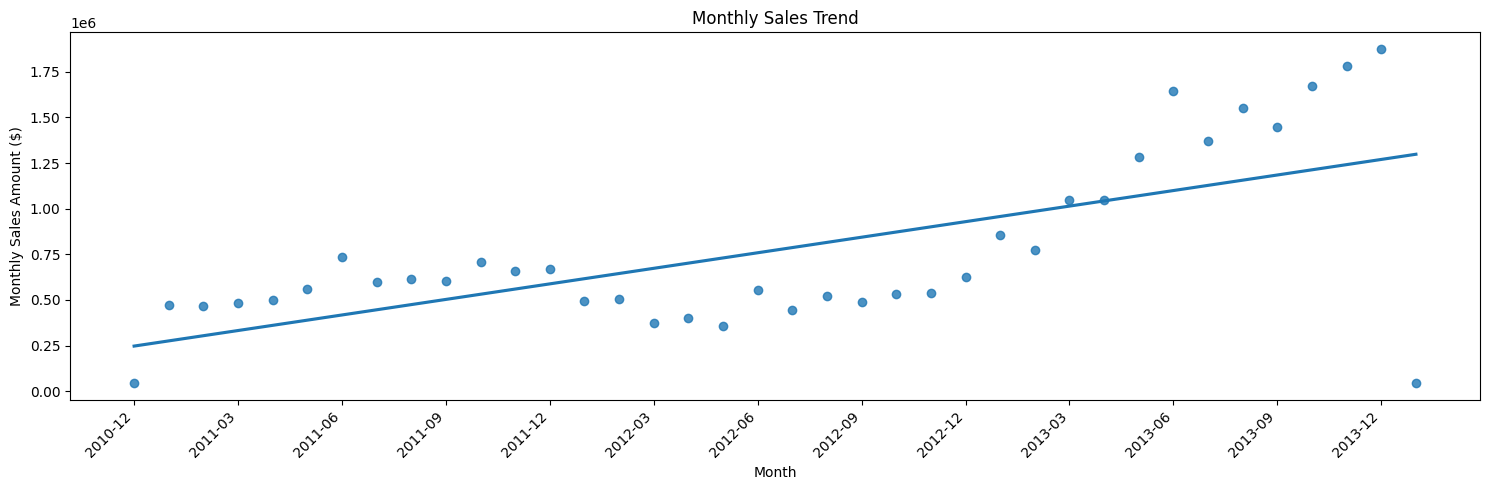

In [38]:
# Aggregate sales by month
monthly_sales = (
    df.groupby(df["OrderDate"].dt.to_period("M"))["SalesAmount"]
      .sum()
      .reset_index()
)

# Convert monthly periods to timestamps
monthly_sales["OrderDate"] = monthly_sales["OrderDate"].dt.to_timestamp()

# Create a sequential month number
monthly_sales["MonthNumber"] = np.arange(len(monthly_sales))

# Plot monthly sales and linear trend line
fig, ax1 = plt.subplots(figsize=(15, 5))

sns.regplot(
    data=monthly_sales,
    x="MonthNumber",
    y="SalesAmount",
    scatter=True,
    ci=None,
    ax=ax1
)

ax1.set(
    title="Monthly Sales Trend",
    xlabel="Month",
    ylabel="Monthly Sales Amount ($)"
)

# Display date labels every three months
tick_positions = monthly_sales["MonthNumber"][::3]
tick_labels = monthly_sales["OrderDate"].dt.strftime("%Y-%m")[::3]

ax1.set_xticks(tick_positions)
ax1.set_xticklabels(tick_labels, rotation=45, ha="right")

plt.tight_layout()
plt.show()